# Carseats: predicting high store sales

Binary classification and clustering on the ISLR **Carseats** dataset (400 stores).
The task is to predict whether a store sells more than 8 units (`High = Sales > 8`)
from price, advertising and store characteristics, and to compare classical
algorithms on it.

## Setup

`carseats_ml` holds the reusable pipeline (loading, model factories, evaluation).
Install it once with `pip install -e .` from the repository root.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

from carseats_ml import data, evaluate, models

## 1. The dataset

In [2]:
raw = data.load_raw()
print(f"{raw.shape[0]} stores, {raw.shape[1]} columns")
raw.head()

400 stores, 11 columns


,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


### The target

`High` is derived from `Sales` with a fixed threshold, so the label is
reproducible and independent of any modelling choice.

In [3]:
frame = data.add_high_target(raw)
frame["High"].value_counts().rename_axis("High").to_frame("stores")

,stores
High,
0,236
1,164


## 2. Feature preparation

Categoricals are one-hot encoded (first level dropped), the data is split 70/30
with a fixed seed, and the numeric features are standardized.

In [4]:
prepared = data.prepare()
print(f"train: {prepared['X_train'].shape}, test: {prepared['X_test'].shape}")
print(f"{len(prepared['feature_names'])} features: {prepared['feature_names']}")

train: (280, 11), test: (120, 11)
11 features: ['CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education', 'ShelveLoc_Good', 'ShelveLoc_Medium', 'Urban_Yes', 'US_Yes']


## 3. K-nearest neighbours

In [5]:
knn_accuracy, knn_predictions = models.fit_and_evaluate(
    models.knn(5),
    prepared["X_train"],
    prepared["y_train"],
    prepared["X_test"],
    prepared["y_test"],
)
print(f"KNN (k=5) accuracy: {knn_accuracy:.3f}")

KNN (k=5) accuracy: 0.767


## 4. Random Forest

The number of trees is swept first, then the forest is inspected for feature
importance.

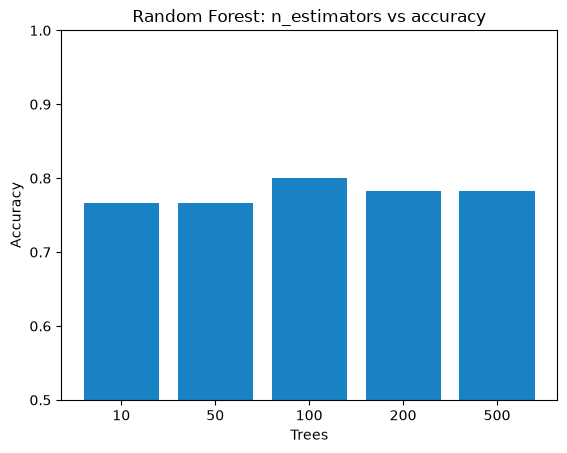

In [6]:
tree_sweep = models.random_forest_sweep(
    prepared["X_train"], prepared["y_train"], prepared["X_test"], prepared["y_test"]
)

plt.bar([str(trees) for trees in tree_sweep], list(tree_sweep.values()), color="#1982C4")
plt.title("Random Forest: n_estimators vs accuracy")
plt.xlabel("Trees")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.0)
plt.show()

In [7]:
rf_model = models.random_forest(100)
rf_accuracy, rf_predictions = models.fit_and_evaluate(
    rf_model,
    prepared["X_train"],
    prepared["y_train"],
    prepared["X_test"],
    prepared["y_test"],
)
print(f"Random Forest (100 trees) accuracy: {rf_accuracy:.3f}")
evaluate.importances(rf_model, prepared["feature_names"]).head(5)

Random Forest (100 trees) accuracy: 0.800


,feature,importance
0,Price,0.242944
1,Age,0.123964
2,CompPrice,0.122586
3,Income,0.113964
4,Advertising,0.112167


## 5. Support Vector Machine

The kernel and the regularization strength `C` are swept before settling on the
final model.

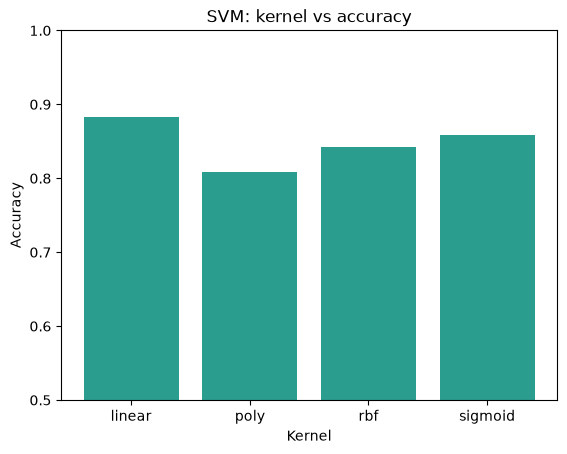

In [8]:
kernel_sweep = models.svm_kernel_sweep(
    prepared["X_train"], prepared["y_train"], prepared["X_test"], prepared["y_test"]
)

plt.bar(list(kernel_sweep), list(kernel_sweep.values()), color="#2A9D8F")
plt.title("SVM: kernel vs accuracy")
plt.xlabel("Kernel")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.0)
plt.show()

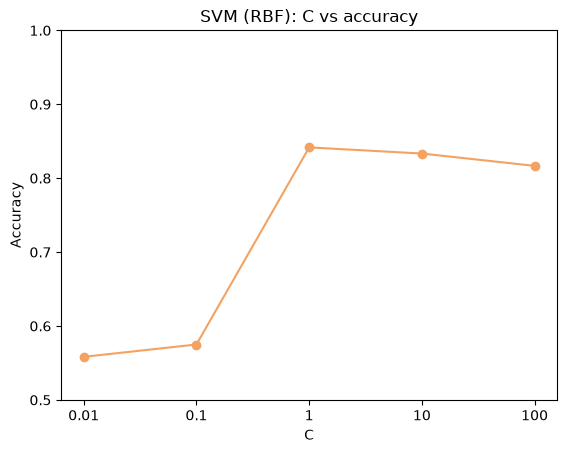

In [9]:
c_sweep = models.svm_c_sweep(
    prepared["X_train"], prepared["y_train"], prepared["X_test"], prepared["y_test"]
)

plt.plot([str(c) for c in c_sweep], list(c_sweep.values()), marker="o", color="#F4A261")
plt.title("SVM (RBF): C vs accuracy")
plt.xlabel("C")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.0)
plt.show()

In [10]:
svm_accuracy, svm_predictions = models.fit_and_evaluate(
    models.svm("linear"),
    prepared["X_train"],
    prepared["y_train"],
    prepared["X_test"],
    prepared["y_test"],
)
print(f"SVM (linear) accuracy: {svm_accuracy:.3f}")

SVM (linear) accuracy: 0.883


## 6. K-Means clustering

An unsupervised view of the stores: K-Means groups them into 4 clusters using
price and income.

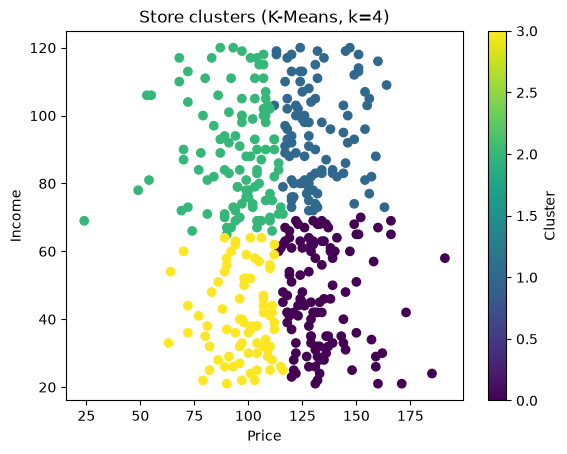

In [11]:
pricing = frame[["Price", "Income"]]
clusters = models.kmeans(4).fit_predict(pricing)

scatter = plt.scatter(pricing["Price"], pricing["Income"], c=clusters, cmap="viridis")
plt.xlabel("Price")
plt.ylabel("Income")
plt.title("Store clusters (K-Means, k=4)")
plt.colorbar(scatter, label="Cluster")
plt.show()

## 7. Model comparison

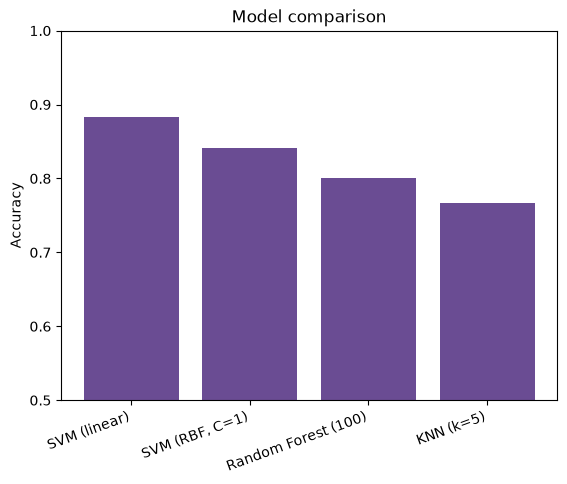

,model,accuracy
0,SVM (linear),0.883333
1,"SVM (RBF, C=1)",0.841667
2,Random Forest (100),0.800000
3,KNN (k=5),0.766667


In [12]:
scores = {
    "KNN (k=5)": knn_accuracy,
    "Random Forest (100)": rf_accuracy,
    "SVM (RBF, C=1)": kernel_sweep["rbf"],
    "SVM (linear)": svm_accuracy,
}

comparison = evaluate.comparison_table(scores)
plt.bar(comparison["model"], comparison["accuracy"], color="#6A4C93")
plt.title("Model comparison")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.0)
plt.xticks(rotation=20, ha="right")
plt.show()
comparison

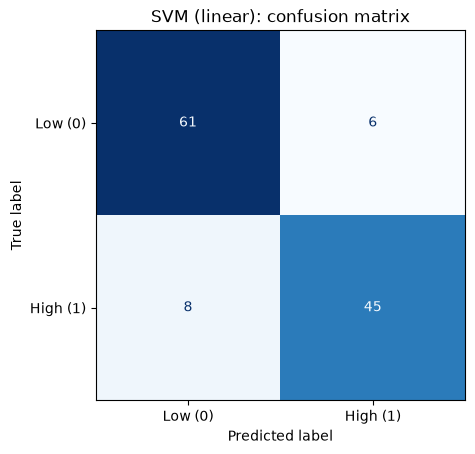

In [13]:
ConfusionMatrixDisplay(
    evaluate.confusion(prepared["y_test"], svm_predictions),
    display_labels=evaluate.CLASS_LABELS,
).plot(cmap="Blues", colorbar=False)
plt.title("SVM (linear): confusion matrix")
plt.show()

## Conclusion

- The **linear SVM** is the most accurate model at **0.883**; the RBF kernel
  reaches 0.842 and the Random Forest 0.800.
- **Price** is by far the most important predictor, followed by Age, CompPrice
  and Income.
- K-Means separates the stores into 4 groups that line up with price/income
  segments.

Every number is reproducible with `python scripts/run_experiments.py` (fixed seeds).